# Supplementary Figure S9c. Cross-cell-type *cis*-*trans* locus counts

Number of loci for each initiating (*cis*, rows) and recipient (*trans*, columns; *trans*-eGene union *trans*-eProgram) cell-type pair among the 1,301 strictly distinct *cis*-*trans* loci (both sides resolved to at least one snRNA-seq cell type and the two cell-type sets disjoint). A locus with several initiating or recipient cell types contributes to every pair it contains (3,134 locus-pair assignments in total). Diagonal cells are empty by construction. Descriptive counts; no statistical test.

Input: `data/Figure_S9c_celltype_pair_counts.rds`

In [1]:
library(ggplot2)
res <- readRDS("data/Figure_S9c_celltype_pair_counts.rds")
head(res)

,trans_method,cis_cell,trans_cell,n_loci,is_diagonal
,<chr>,<fct>,<fct>,<int>,<lgl>
1,combined trans,Exc,Exc,0,TRUE
2,combined trans,Inh,Exc,28,FALSE
3,combined trans,Ast,Exc,44,FALSE
4,combined trans,Oli,Exc,44,FALSE
5,combined trans,OPC,Exc,19,FALSE
6,combined trans,Mic,Exc,20,FALSE


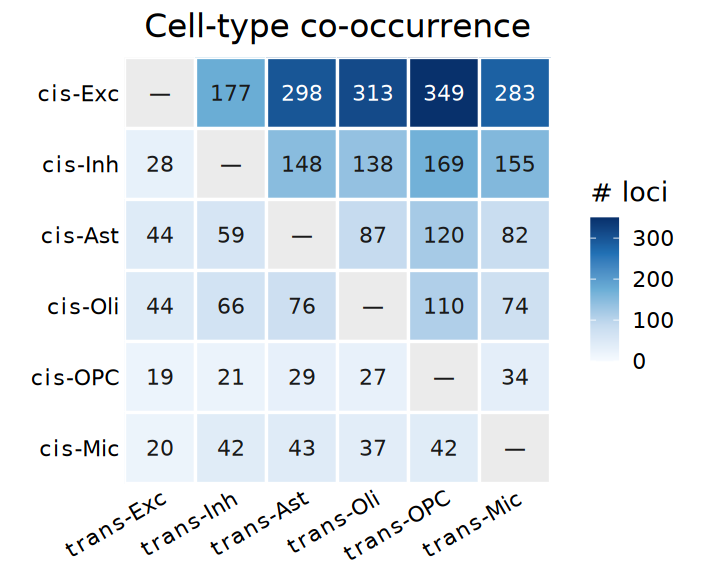

In [2]:
res$fill <- ifelse(res$is_diagonal, NA, res$n_loci)
res$label <- ifelse(res$is_diagonal, "\u2014", res$n_loci)
res$cis_cell <- factor(res$cis_cell, levels = rev(levels(res$cis_cell)))

p <- ggplot(res, aes(x = trans_cell, y = cis_cell)) +
  geom_tile(aes(fill = fill), colour = "white", linewidth = 0.7) +
  geom_text(aes(label = label, colour = !is.na(fill) & fill > 0.55 * max(fill, na.rm = TRUE)),
            size = 4.5, show.legend = FALSE) +
  scale_colour_manual(values = c(`TRUE` = "white", `FALSE` = "grey10"), guide = "none") +
  scale_fill_gradientn(colours = c("#F7FBFF", "#C6DBEF", "#6BAED6", "#2171B5", "#08306B"),
                       limits = c(0, 350), na.value = "grey92", name = "# loci") +
  scale_x_discrete(labels = function(x) parse(text = paste0("italic(trans)*'-", x, "'")),
                   expand = c(0, 0)) +
  scale_y_discrete(labels = function(x) parse(text = paste0("italic(cis)*'-", x, "'")),
                   expand = c(0, 0)) +
  coord_fixed() +
  labs(x = NULL, y = NULL, title = "Cell-type co-occurrence") +
  theme_classic(base_size = 16) +
  theme(plot.title = element_text(hjust = 0.5), axis.line = element_blank(),
        axis.ticks = element_blank(), axis.text.x = element_text(angle = 30, hjust = 1))

options(repr.plot.width = 6, repr.plot.height = 4.8)
p